In [9]:
import torch
from cvnets.models.classification.mobilevit_v2 import MobileViTv2 
import torch
import numpy as np
from PIL import Image
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import ToTensor, Resize
import matplotlib.pyplot as plt
from torchmetrics.functional.image import structural_similarity_index_measure as SSIM
import argparse
import os

In [10]:
#Testing with local paths

TEST_PATCH_EXTENDED = '../test_data/patches_bad_only'
GOOD_PATCH_EXTENDED = '../test_data/patches_good_only'
PATCH_DIR_CL = '../test_data/classifier_dataset/train'
TEST_DIR_CL = '../test_data/classifier_dataset/test'
TEST_PATCH_G = '../test_data/model_test_patch_g'
TEST_PATCH_B = '../test_data/model_test_patch_b'
baseline_model = '../models/baseline_anomaly_model.pth'
bm_ssim = '../models/baseline_with_ssim_best.pth'
mvit_upgrade = '../models/mvit_upgraded.pth'
anet_disc = '../models/anet_gan_best.pth'
strawberry_net = '../models/strawberry_net_best.pth'

In [11]:
PATCH_SIZE = 128
EPOCHS = 50
BATCH_SIZE = 16
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [12]:
transform_patch = transforms.Compose([
    transforms.Resize((PATCH_SIZE, PATCH_SIZE)),
    transforms.ToTensor()
])

class PatchDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = []
        for subdir in os.listdir(root_dir):
            # Check if it's a directory
            if not os.path.isdir(os.path.join(root_dir, subdir)):
                continue
            subdir_path = os.path.join(self.root_dir, subdir)
            for f in os.listdir(subdir_path):
                if f.endswith('.jpg'):
                    self.image_files.append(os.path.join(subdir, f))
    
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image

    
def get_dataloader(patch_dir, batch_size=BATCH_SIZE):
    patch_dataset = PatchDataset(patch_dir, transform=transform_patch)
    patch_loader = DataLoader(patch_dataset, batch_size=batch_size, shuffle=True, num_workers=0) #no multiprocessing for debugging purposes
    
    return patch_loader


In [13]:
# Decoder class to reconstruct the image from encoder features
class Decoder(nn.Module):
    def __init__(self, in_channels, out_channels=3):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        
        # Convolutional layers with batch norm and ReLU
        self.conv1 = nn.Conv2d(in_channels, 128, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(128)
        
        self.conv2 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(32)
        
        self.conv4 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(16)
        
        self.conv5 = nn.Conv2d(16, out_channels, kernel_size=3, padding=1)
        
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.upsample(x)
        x = self.relu(self.bn1(self.conv1(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn2(self.conv2(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn3(self.conv3(x)))
        
        x = self.upsample(x)
        x = self.relu(self.bn4(self.conv4(x)))
        
        x = self.upsample(x)
        x = self.conv5(x)
        return self.sigmoid(x)

# Autoencoder class combining MobileViTv2 encoder and custom decoder
class MobileViTv2Autoencoder(nn.Module):
    def __init__(self,opts):
        super().__init__()
        # Initialize the MobileViTv2 as the encoder
        self.encoder = MobileViTv2(opts)

        # Remove the classifier since we are doing reconstruction, not classification
        del self.encoder.classifier
        
        # Get the number of output channels from layer_5
        in_channels = self.encoder.model_conf_dict["layer5"]["out"]
        
        # Initialize the decoder
        self.decoder = Decoder(in_channels)

    def forward(self, x):
        # Encoder path
        x = self.encoder.conv_1(x)
        x = self.encoder.layer_1(x)
        x = self.encoder.layer_2(x)
        x = self.encoder.layer_3(x)
        x = self.encoder.layer_4(x)
        x = self.encoder.layer_5(x)
        
        # Decoder path
        x = self.decoder(x)
        return x

In [14]:
class SSIMLoss(nn.Module):
    def __init__(self, data_range=None):
        super().__init__()
        self.data_range = data_range

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        """
        Compute 1 - SSIM(y_pred, y_true). SSIM returns [0,1], higher is better.
        """
        return 1.0 - SSIM(y_pred, y_true, data_range=self.data_range, reduction='elementwise_mean')

In [15]:
def train_autoencoder(model: nn.Module,
                      train_loader: DataLoader,
                      num_epochs: int,
                      lr: float = 1e-3):
    model = model.to(DEVICE)
    criterion = SSIMLoss(data_range=None)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10)

    best_train_loss = float('inf')
    train_losses = []  # Track losses for plotting

    for epoch in range(1, num_epochs+1):
        # -- Training --
        model.train()
        train_loss = 0.0
        for imgs in train_loader:
            imgs = imgs.to(DEVICE)
            optimizer.zero_grad()
            recons = model(imgs)
            loss = criterion(recons, imgs)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)

        train_loss /= len(train_loader.dataset)
        train_losses.append(train_loss)  # Store loss for plotting
        
        print(f"Epoch {epoch}/{num_epochs} | Train Loss: {train_loss:.6f}")
        if train_loss < best_train_loss:
            best_train_loss = train_loss
            torch.save(model.state_dict(), "best_autoencoder_3.pth")
            print(f"Best model saved with loss: {best_train_loss:.6f}")

        scheduler.step(train_loss) 

    print("Training complete")
    
    # Plot the training loss
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, num_epochs+1), train_losses, linestyle='-')
    plt.title('Training Loss vs. Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    plt.xticks(range(1, num_epochs+1, max(1, num_epochs//10)))  # Set sensible x-ticks
    
    # Add a horizontal line at the best loss value
    plt.axhline(y=best_train_loss, color='r', linestyle='--', 
                label=f'Best Loss: {best_train_loss:.6f}')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return train_losses

In [16]:
patch_loader = get_dataloader(GOOD_PATCH_EXTENDED, BATCH_SIZE)

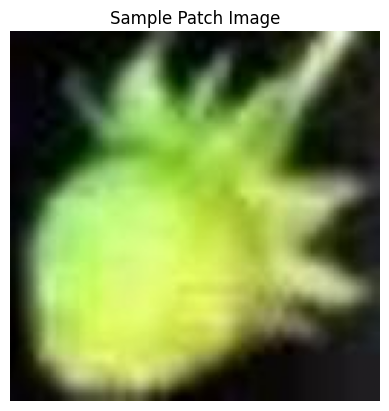

In [17]:
# Get one batch from the patch DataLoader and display the first image
images = next(iter(patch_loader))
img = images[0].permute(1, 2, 0).cpu().numpy()
plt.imshow(img)
plt.title("Sample Patch Image")
plt.axis('off')
plt.show()

In [18]:
# MobileViTV2 uses the get_configuration function inside its model
# It uses default values for all parameters except these:
opts = argparse.Namespace()
# BaseImageEncoder flags (defaults)
setattr(opts, "model.classification.gradient_checkpointing", False)
setattr(opts, "model.classification.layer_wise_lr_decay_rate", 1.0)
setattr(opts, "model.classification.enable_layer_wise_lr_decay", False)
setattr(opts, "model.normalization.name", "batch_norm")
setattr(opts, "model.normalization.groups", 1)
setattr(opts, "model.normalization.momentum", 0.1)
setattr(opts, "model.normalization.weight_decay", 0.00001)
setattr(opts, "model.normalization.eps", 1e-5)
setattr(opts, "model.activation.name", "relu")
setattr(opts, "model.activation.inplace", True)
setattr(opts, "model.activation.neg_slope", 0.0)


In [19]:
model = MobileViTv2Autoencoder(opts)
model.load_state_dict(torch.load(mvit_upgrade, map_location=DEVICE))

<All keys matched successfully>

#### Confirming model parameters:

In [20]:
model.encoder.model_conf_dict["layer5"]["out"]

512

In [21]:
model.encoder.layer_1

Sequential(
  (0): InvertedResidual(in_channels=32, out_channels=64, stride=1, exp=2, dilation=1, skip_conn=False)
)

In [22]:
model.encoder.layer_2

Sequential(
  (0): InvertedResidual(in_channels=64, out_channels=128, stride=2, exp=2, dilation=1, skip_conn=False)
  (1): InvertedResidual(in_channels=128, out_channels=128, stride=1, exp=2, dilation=1, skip_conn=True)
)

In [23]:
model.encoder.layer_3

Sequential(
  (0): InvertedResidual(in_channels=128, out_channels=256, stride=2, exp=2, dilation=1, skip_conn=False)
  (1): MobileViTBlockv2(
  	 Local representations
  		 Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=256, bias=False, normalization=BatchNorm2d, activation=ReLU)
  		 Conv2d(256, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
  	 Global representations with patch size of 2x2
  		 LinearAttnFFN(embed_dim=128, ffn_dim=256, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=128, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=128, ffn_dim=256, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=128, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LayerNorm2D_NCHW(num_channels=128, eps=1e-05, affine=True)
  		 Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False, normalization=BatchNorm2d)
  )
)

In [24]:
model.encoder.layer_4

Sequential(
  (0): InvertedResidual(in_channels=256, out_channels=384, stride=2, exp=2, dilation=1, skip_conn=False)
  (1): MobileViTBlockv2(
  	 Local representations
  		 Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=384, bias=False, normalization=BatchNorm2d, activation=ReLU)
  		 Conv2d(384, 192, kernel_size=(1, 1), stride=(1, 1), bias=False)
  	 Global representations with patch size of 2x2
  		 LinearAttnFFN(embed_dim=192, ffn_dim=384, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=192, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=192, ffn_dim=384, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=192, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=192, ffn_dim=384, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=192, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=192, ffn_dim=384, dropout=0.0, ffn_dropout=0.0, 

In [25]:
model.encoder.layer_5

Sequential(
  (0): InvertedResidual(in_channels=384, out_channels=512, stride=2, exp=2, dilation=1, skip_conn=False)
  (1): MobileViTBlockv2(
  	 Local representations
  		 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=512, bias=False, normalization=BatchNorm2d, activation=ReLU)
  		 Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  	 Global representations with patch size of 2x2
  		 LinearAttnFFN(embed_dim=256, ffn_dim=512, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=256, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=256, ffn_dim=512, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=256, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LinearAttnFFN(embed_dim=256, ffn_dim=512, dropout=0.0, ffn_dropout=0.0, attn_fn=LinearSelfAttention(embed_dim=256, attn_dropout=0.0), norm_layer=layer_norm_2d)
  		 LayerNorm2D_NCHW(num_channels=256, eps=1e-05, affine=True)
  		 Conv2d(2

Showing an example training run:

Loaded model from mvit_latest.pth
Continuing training on cuda...
Epoch 1/153 | Train Loss: 0.029108
Best model saved with loss: 0.029108
Epoch 2/153 | Train Loss: 0.029696
Epoch 3/153 | Train Loss: 0.029740
Epoch 4/153 | Train Loss: 0.029546
Epoch 5/153 | Train Loss: 0.029543
Epoch 6/153 | Train Loss: 0.029653
Epoch 7/153 | Train Loss: 0.029565
Epoch 8/153 | Train Loss: 0.028840
Best model saved with loss: 0.028840
Epoch 9/153 | Train Loss: 0.028377
Best model saved with loss: 0.028377
Epoch 10/153 | Train Loss: 0.028353
Best model saved with loss: 0.028353
Epoch 11/153 | Train Loss: 0.028481
Epoch 12/153 | Train Loss: 0.028385
Epoch 13/153 | Train Loss: 0.028495
Epoch 14/153 | Train Loss: 0.028460
Epoch 15/153 | Train Loss: 0.028619
Epoch 16/153 | Train Loss: 0.028501
Epoch 17/153 | Train Loss: 0.028194
Best model saved with loss: 0.028194
Epoch 18/153 | Train Loss: 0.028055
Best model saved with loss: 0.028055
Epoch 19/153 | Train Loss: 0.028069
Epoch 20/153 | Train Loss: 0.028116
Ep

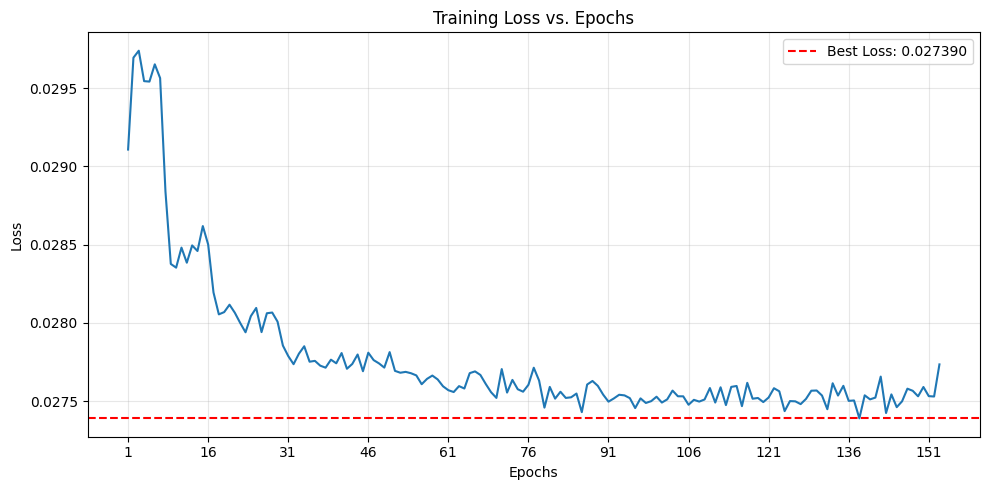

[0.029108234821569292,
 0.02969567674074986,
 0.029740181080130643,
 0.0295456236647081,
 0.029542828509768568,
 0.029653077850456795,
 0.029565183999310476,
 0.028840219430323822,
 0.028377022135370668,
 0.028353303388518367,
 0.02848132610526401,
 0.02838491797960595,
 0.028495402761207995,
 0.028459653579192775,
 0.028619055497451244,
 0.028501258237314676,
 0.028194428465676453,
 0.028054619739016615,
 0.028069016237283553,
 0.028116333392239356,
 0.028064736716198982,
 0.027999812729085548,
 0.02794005355374963,
 0.028043462529868324,
 0.028095636770296056,
 0.027941101897286505,
 0.028061743443839823,
 0.028066245879108387,
 0.0280080439200389,
 0.027855202260456857,
 0.027788269427395606,
 0.027736120959174316,
 0.027803142454786406,
 0.0278507396129572,
 0.02775196275456418,
 0.027757322706096033,
 0.027726589247237806,
 0.02771376208125467,
 0.02776488068799948,
 0.02774182339355311,
 0.02780723032717249,
 0.02770693080369816,
 0.02773754171622816,
 0.027798006444219675,
 0.02

In [ ]:
# Training with scheduler now
model_path = 'mvit_latest.pth'
loaded_model = MobileViTv2Autoencoder(opts)
# Continue training the model
loaded_model.load_state_dict(torch.load(model_path, map_location=DEVICE))
loaded_model.train()
print(f"Loaded model from {model_path}")
loaded_model = loaded_model.to(DEVICE)
print(f"Continuing training on {DEVICE}...")
train_autoencoder(loaded_model, patch_loader, num_epochs=153)

Model trained for 1500 epochs now